# Day 9 – Exploratory Data Analysis (EDA) using Python

**Objective:** Explore the cleaned Day 8 student dataset, summarize it statistically, discover patterns, create visualizations, and document five evidence-based insights.

> This project uses the cleaned student dataset from Day 8. It contains a small sample of 8 records, so findings are descriptive and should not be generalized to a larger student population.

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Run from the project root or from the notebooks folder
try:
    df = pd.read_csv('data/cleaned_student_data.csv')
except FileNotFoundError:
    df = pd.read_csv('../data/cleaned_student_data.csv')

df.head()

,student_name,roll_number,department,age,marks,attendance,email
0,Asha Rao,23AI001,AI & ML,20.0,88.0,92.0,asha@example.com
1,Rahul Kumar,23AI002,CSE,21.0,76.0,85.0,rahul@example.com
2,Meena Das,23AI003,ECE,20.5,91.0,90.0,meena@example.com
3,Vikram Singh,23AI004,CSE,22.0,84.0,78.0,vikram@example.com
4,Unknown,23AI005,AI & ML,19.0,67.0,88.0,student5@example.com


## 2. Understand the dataset

In [2]:
print('Shape:', df.shape)
display(df.head())
df.info()
print('Duplicate rows:', df.duplicated().sum())
print('Missing values by column:\n', df.isna().sum())

Shape: (8, 7)


,student_name,roll_number,department,age,marks,attendance,email
0,Asha Rao,23AI001,AI & ML,20.0,88.0,92.0,asha@example.com
1,Rahul Kumar,23AI002,CSE,21.0,76.0,85.0,rahul@example.com
2,Meena Das,23AI003,ECE,20.5,91.0,90.0,meena@example.com
3,Vikram Singh,23AI004,CSE,22.0,84.0,78.0,vikram@example.com
4,Unknown,23AI005,AI & ML,19.0,67.0,88.0,student5@example.com


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   student_name  8 non-null      object 
 1   roll_number   8 non-null      object 
 2   department    8 non-null      object 
 3   age           8 non-null      float64
 4   marks         8 non-null      float64
 5   attendance    8 non-null      float64
 6   email         8 non-null      object 
dtypes: float64(3), object(4)
memory usage: 580.0+ bytes
Duplicate rows: 0
Missing values by column:
 student_name    0
roll_number     0
department      0
age             0
marks           0
attendance      0
email           0
dtype: int64


## 3. Descriptive statistics

In [3]:
display(df.describe())
display(df.describe(include='object'))
print('Average marks:', round(df['marks'].mean(), 2))
print('Median marks:', round(df['marks'].median(), 2))
print('Average attendance:', round(df['attendance'].mean(), 2))
print('Correlation between attendance and marks:', round(df['attendance'].corr(df['marks']), 3))

,age,marks,attendance
count,8.000000,8.000000,8.000000
mean,20.500000,82.250000,89.125000
std,0.886405,9.528154,5.642631
min,19.000000,67.000000,78.000000
25%,20.000000,75.250000,87.250000
50%,20.500000,84.000000,90.000000
75%,21.000000,88.750000,92.500000
max,22.000000,95.000000,96.000000


,student_name,roll_number,department,email
count,8,8,8,8
unique,8,8,3,8
top,Asha Rao,23AI001,AI & ML,asha@example.com
freq,1,1,3,1


Average marks: 82.25
Median marks: 84.0
Average attendance: 89.12
Correlation between attendance and marks: 0.361


## 4. Visualizations

### 4.1 Average marks by department

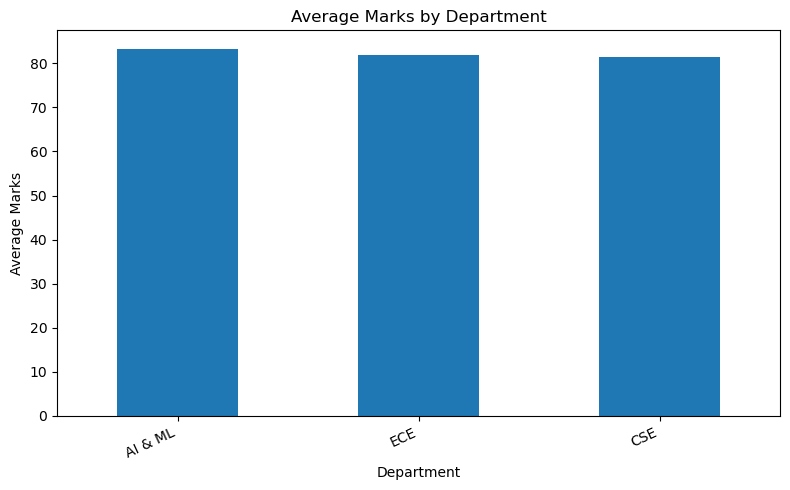

In [4]:
df.groupby('department')['marks'].mean().sort_values(ascending=False).plot(kind='bar', figsize=(8,5))
plt.title('Average Marks by Department'); plt.xlabel('Department'); plt.ylabel('Average Marks'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

### 4.2 Distribution of marks

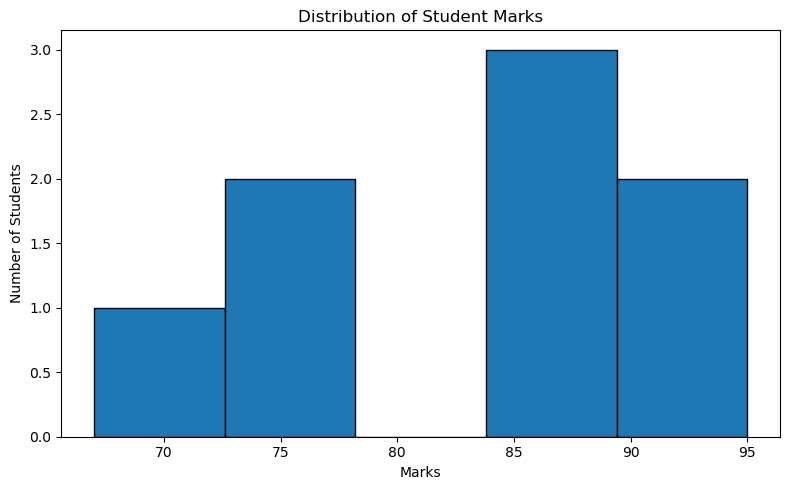

In [5]:
plt.figure(figsize=(8,5)); plt.hist(df['marks'], bins=5, edgecolor='black')
plt.title('Distribution of Student Marks'); plt.xlabel('Marks'); plt.ylabel('Number of Students'); plt.tight_layout(); plt.show()

### 4.3 Attendance versus marks

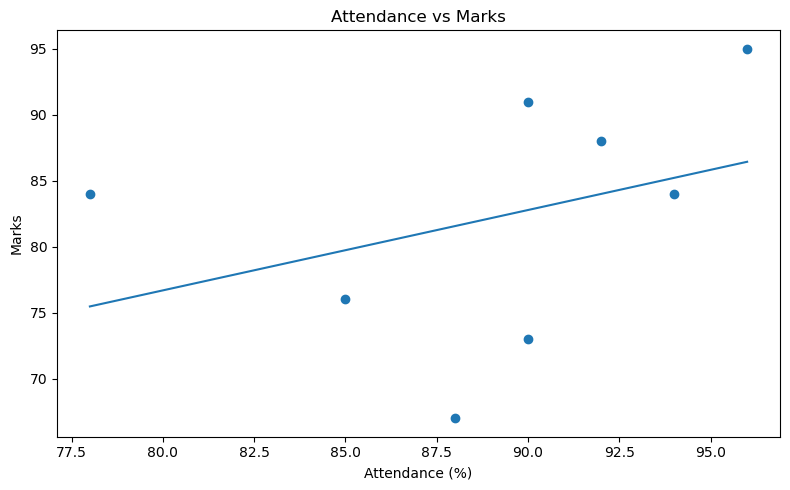

In [6]:
plt.figure(figsize=(8,5)); plt.scatter(df['attendance'], df['marks'])
z = np.polyfit(df['attendance'], df['marks'], 1); p = np.poly1d(z)
xs = np.linspace(df['attendance'].min(), df['attendance'].max(), 100); plt.plot(xs, p(xs))
plt.title('Attendance vs Marks'); plt.xlabel('Attendance (%)'); plt.ylabel('Marks'); plt.tight_layout(); plt.show()

### 4.4 Average attendance by department

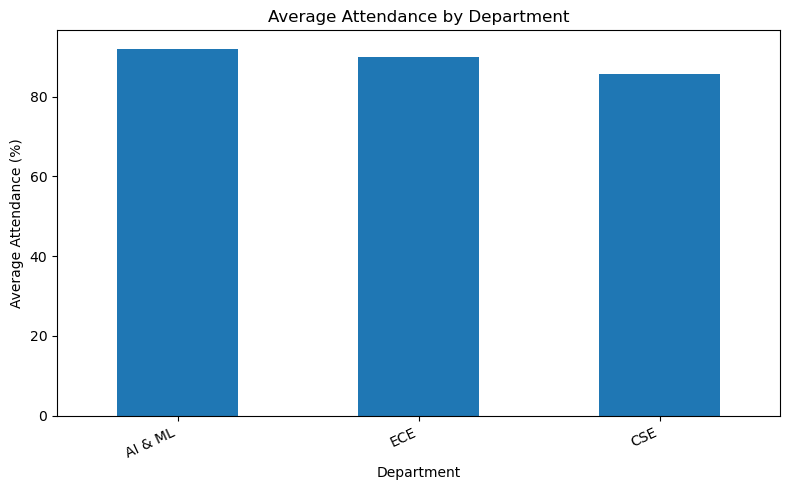

In [7]:
df.groupby('department')['attendance'].mean().sort_values(ascending=False).plot(kind='bar', figsize=(8,5))
plt.title('Average Attendance by Department'); plt.xlabel('Department'); plt.ylabel('Average Attendance (%)'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

### 4.5 Marks spread by department

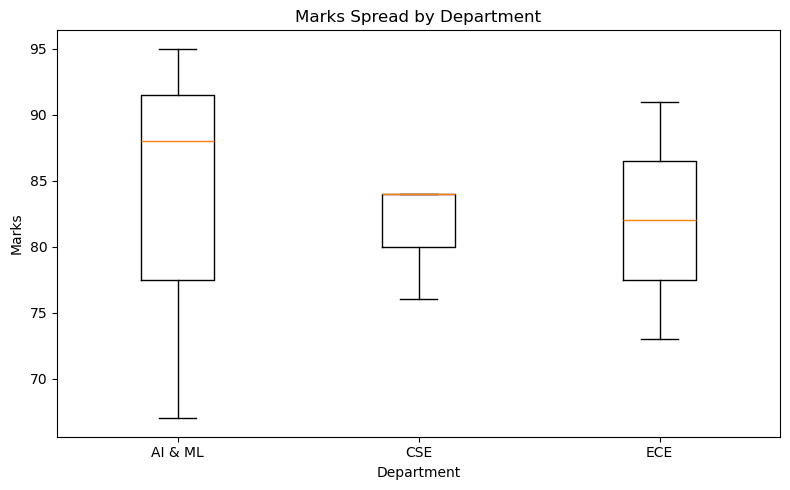

In [8]:
departments = df['department'].unique()
plt.figure(figsize=(8,5)); plt.boxplot([df.loc[df.department == d, 'marks'].values for d in departments], tick_labels=departments)
plt.title('Marks Spread by Department'); plt.xlabel('Department'); plt.ylabel('Marks'); plt.tight_layout(); plt.show()

## 5. Five business / academic insights

In [9]:
insights = [
    f"Overall average marks are {df['marks'].mean():.2f} out of 100.",
    f"{df.groupby('department')['marks'].mean().idxmax()} has the highest average marks ({df.groupby('department')['marks'].mean().max():.2f}) in this sample.",
    f"{df.groupby('department')['attendance'].mean().idxmax()} has the highest average attendance ({df.groupby('department')['attendance'].mean().max():.2f}%).",
    f"The correlation between attendance and marks is {df['attendance'].corr(df['marks']):.2f}; in this small sample it indicates a positive/negative relationship depending on the sign.",
    f"Marks range from {df['marks'].min():.0f} to {df['marks'].max():.0f}, a spread of {df['marks'].max()-df['marks'].min():.0f} points."
]
for i, insight in enumerate(insights, 1): print(f'{i}. {insight}')

1. Overall average marks are 82.25 out of 100.
2. AI & ML has the highest average marks (83.33) in this sample.
3. AI & ML has the highest average attendance (92.00%).
4. The correlation between attendance and marks is 0.36; in this small sample it indicates a positive/negative relationship depending on the sign.
5. Marks range from 67 to 95, a spread of 28 points.


## 6. Export outputs

In [10]:
import os
os.makedirs('reports', exist_ok=True)
df.describe(include='all').transpose().to_csv('reports/descriptive_statistics.csv')
print('Saved descriptive statistics to reports/descriptive_statistics.csv')

Saved descriptive statistics to reports/descriptive_statistics.csv


## 7. Conclusion

EDA helps summarize data and discover patterns before model training or decision-making. This notebook explored student marks and attendance by using descriptive statistics and five visualizations. Since the dataset has only eight records, conclusions should be treated as preliminary and revisited with a larger dataset.